In [17]:

!pip -q install networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from collections import deque
import heapq


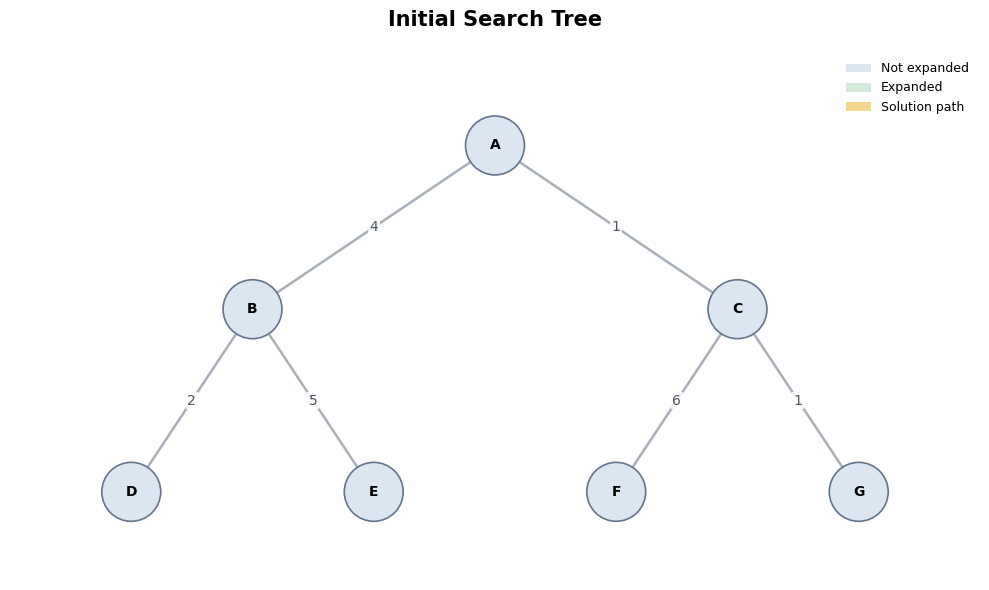

In [18]:

# Build the search tree
G = nx.DiGraph()

edges = [
    ("A", "B", 4),
    ("A", "C", 1),
    ("B", "D", 2),
    ("B", "E", 5),
    ("C", "F", 6),
    ("C", "G", 1)
]

G.add_weighted_edges_from(edges)

# Store the children of each node
graph = {
    node: list(G.successors(node))
    for node in G.nodes()
}

start = "A"
goal = "F"

# Positions of the nodes
pos = {
    "A": (0, 3.1),
    "B": (-1.5, 1.8),
    "C": (1.5, 1.8),
    "D": (-2.25, 0.35),
    "E": (-0.75, 0.35),
    "F": (0.75, 0.35),
    "G": (2.25, 0.35)
}


def draw_graph(steps=None, path=None, title="Search Tree"):

    if steps is None:
        steps = []

    if path is None:
        path = []

    visited = set(steps)
    path_nodes = set(path)
    path_edges = set(zip(path, path[1:]))

    # Record the expansion number of each node
    step_numbers = {}

    for i, node in enumerate(steps, start=1):
        if node not in step_numbers:
            step_numbers[node] = i

    labels = {
        node: f"{node}\n({step_numbers[node]})"
        if node in step_numbers else node
        for node in G.nodes()
    }

    # Choose colors for the nodes
    node_colors = []

    for node in G.nodes():

        if node in path_nodes:
            node_colors.append("#F3D58B")

        elif node in visited:
            node_colors.append("#D5E9DA")

        else:
            node_colors.append("#DCE6F0")

    # Highlight the solution path
    edge_colors = [
        "#D97757" if (u, v) in path_edges else "#A8B0BA"
        for u, v in G.edges()
    ]

    fig, ax = plt.subplots(figsize=(10, 6))

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        arrows=True,
        arrowsize=18,
        width=1.8,
        edge_color=edge_colors
    )

    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_size=1800,
        node_color=node_colors,
        edgecolors="#64748B",
        linewidths=1.2
    )

    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        ax=ax,
        font_size=10,
        font_weight="bold"
    )

    # Show the cost of each edge
    edge_labels = nx.get_edge_attributes(G, "weight")

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        ax=ax,
        font_size=10,
        font_color="#4B5563",
        rotate=False,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85,
            pad=1
        )
    )

    # Add a color legend
    legend_items = [
        Patch(facecolor="#DCE6F0", label="Not expanded"),
        Patch(facecolor="#D5E9DA", label="Expanded"),
        Patch(facecolor="#F3D58B", label="Solution path")
    ]

    ax.legend(
        handles=legend_items,
        loc="upper right",
        frameon=False,
        fontsize=9
    )

    ax.set_title(
        title,
        fontsize=15,
        fontweight="semibold",
        pad=18
    )

    if steps:
        ax.text(
            0.5,
            0.02,
            "Expansion order: " + " -> ".join(steps),
            transform=ax.transAxes,
            ha="center",
            fontsize=10
        )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.35, 3.85)
    ax.axis("off")

    plt.tight_layout()
    plt.show()


# Display the original tree
draw_graph(title="Initial Search Tree")


In [19]:

def make_path(parent, goal):

    if goal not in parent:
        return []

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    return path[::-1]


Expansion Order: A -> B -> C -> D -> E -> F
Goal Found: True
Solution Path: A -> C -> F


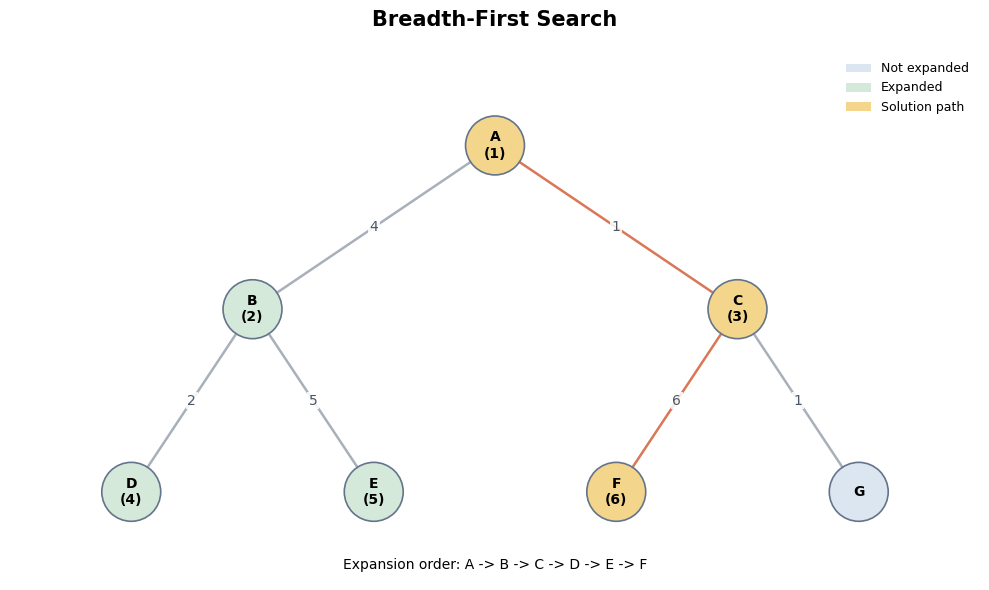

In [20]:

def bfs(start, goal):

    queue = deque([start])
    discovered = {start}
    parent = {start: None}
    steps = []

    while queue:

        node = queue.popleft()
        steps.append(node)

        if node == goal:
            break

        for child in graph[node]:

            if child not in discovered:

                discovered.add(child)
                parent[child] = node
                queue.append(child)

    found = bool(steps) and steps[-1] == goal
    path = make_path(parent, goal) if found else []

    print("Expansion Order:", " -> ".join(steps))
    print("Goal Found:", found)
    print("Solution Path:", " -> ".join(path) if found else "Not Found")

    draw_graph(steps, path, "Breadth-First Search")


bfs(start, goal)


Expansion Order: A -> B -> D -> E -> C -> F
Goal Found: True
Solution Path: A -> C -> F


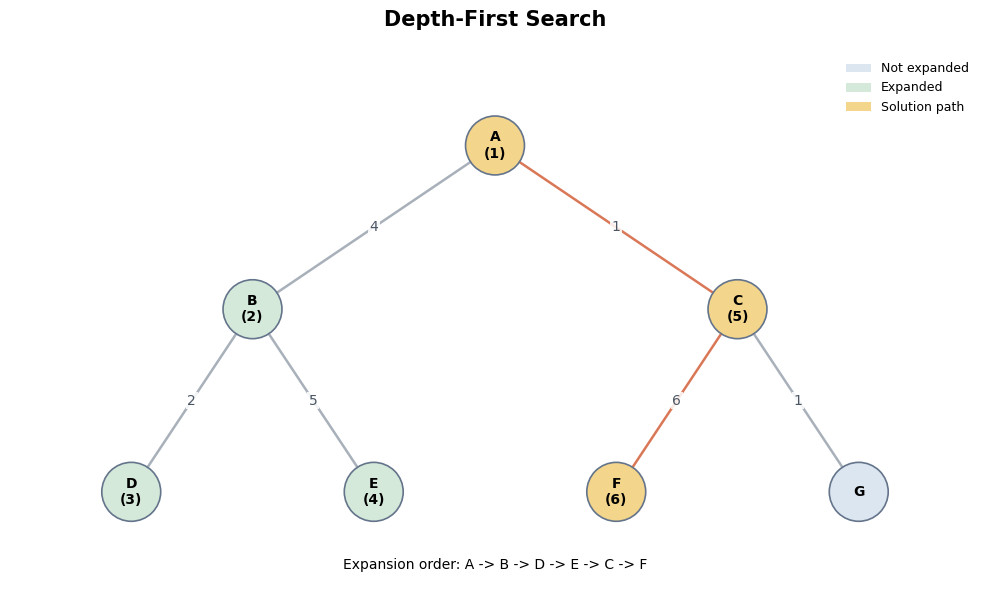

In [21]:

def dfs(start, goal):

    stack = [start]
    discovered = {start}
    parent = {start: None}
    steps = []

    while stack:

        node = stack.pop()
        steps.append(node)

        if node == goal:
            break

        for child in reversed(graph[node]):

            if child not in discovered:

                discovered.add(child)
                parent[child] = node
                stack.append(child)

    found = bool(steps) and steps[-1] == goal
    path = make_path(parent, goal) if found else []

    print("Expansion Order:", " -> ".join(steps))
    print("Goal Found:", found)
    print("Solution Path:", " -> ".join(path) if found else "Not Found")

    draw_graph(steps, path, "Depth-First Search")


dfs(start, goal)


Depth Limit: 2
Expansion Order: A -> B -> D -> E -> C -> F
Goal Found: True
Solution Path: A -> C -> F


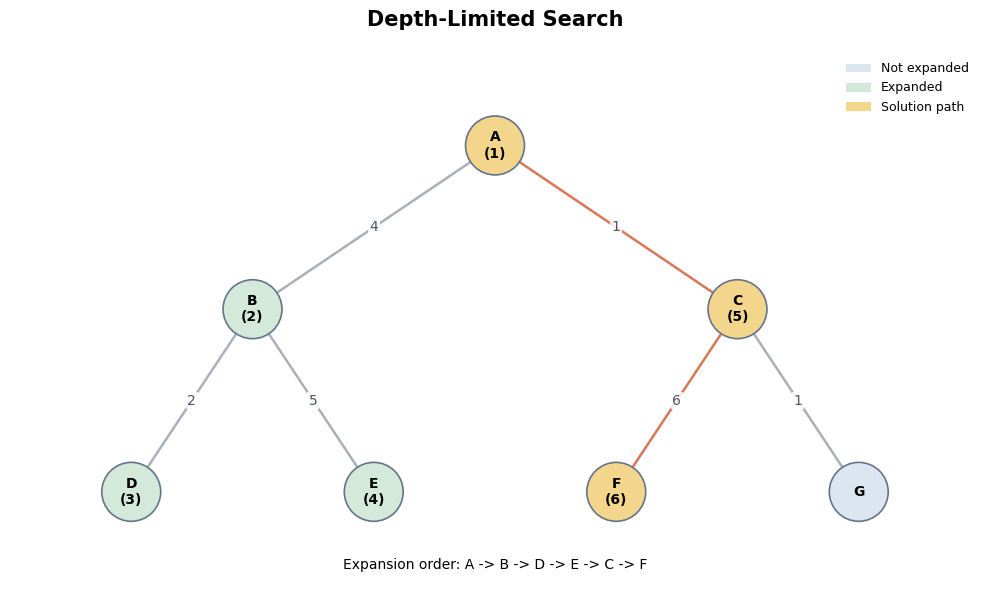

In [22]:

def dls(current, goal, limit, path, steps):

    steps.append(current)

    if current == goal:
        return True

    if limit == 0:
        return False

    for child in graph[current]:

        path.append(child)

        if dls(child, goal, limit - 1, path, steps):
            return True

        path.pop()

    return False


limit = 2

path = [start]
steps = []

found = dls(start, goal, limit, path, steps)

print("Depth Limit:", limit)
print("Expansion Order:", " -> ".join(steps))
print("Goal Found:", found)
print("Solution Path:", " -> ".join(path) if found else "Not Found")

draw_graph(steps, path if found else [], "Depth-Limited Search")



Depth Limit: 0
Expansion Order: A
Goal Found: False
Solution Path: Not Found


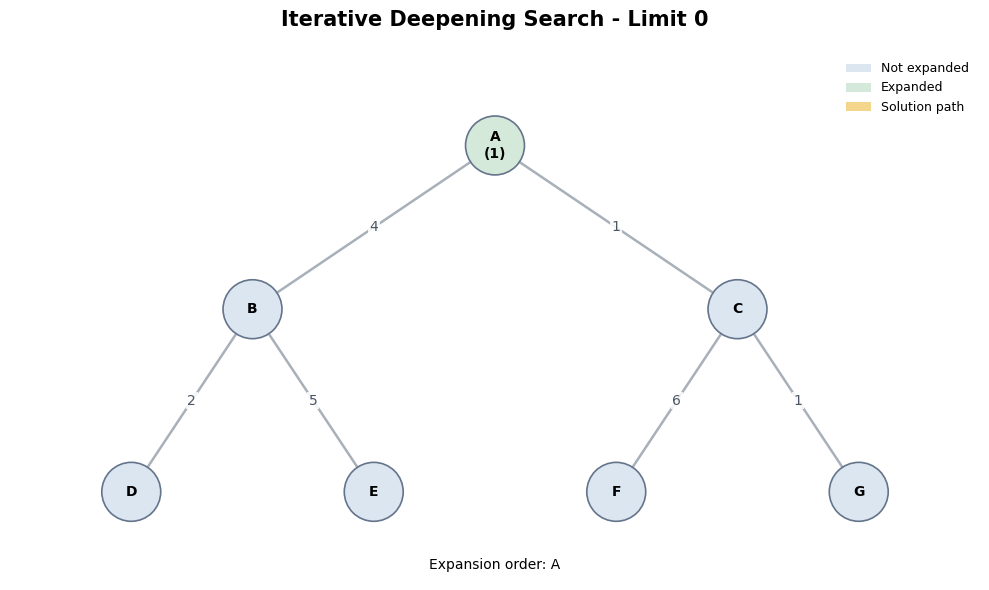


Depth Limit: 1
Expansion Order: A -> B -> C
Goal Found: False
Solution Path: Not Found


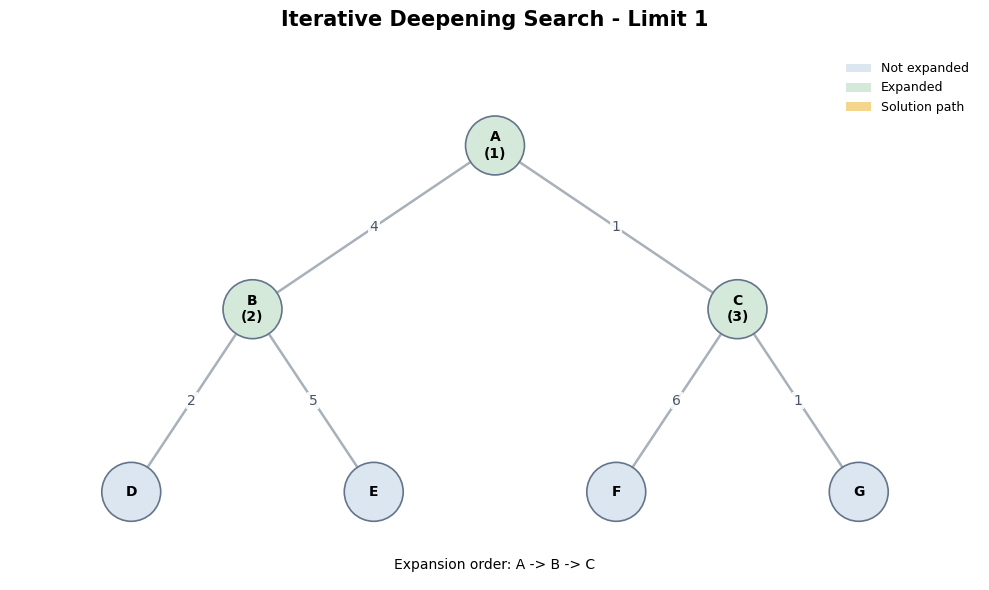


Depth Limit: 2
Expansion Order: A -> B -> D -> E -> C -> F
Goal Found: True
Solution Path: A -> C -> F


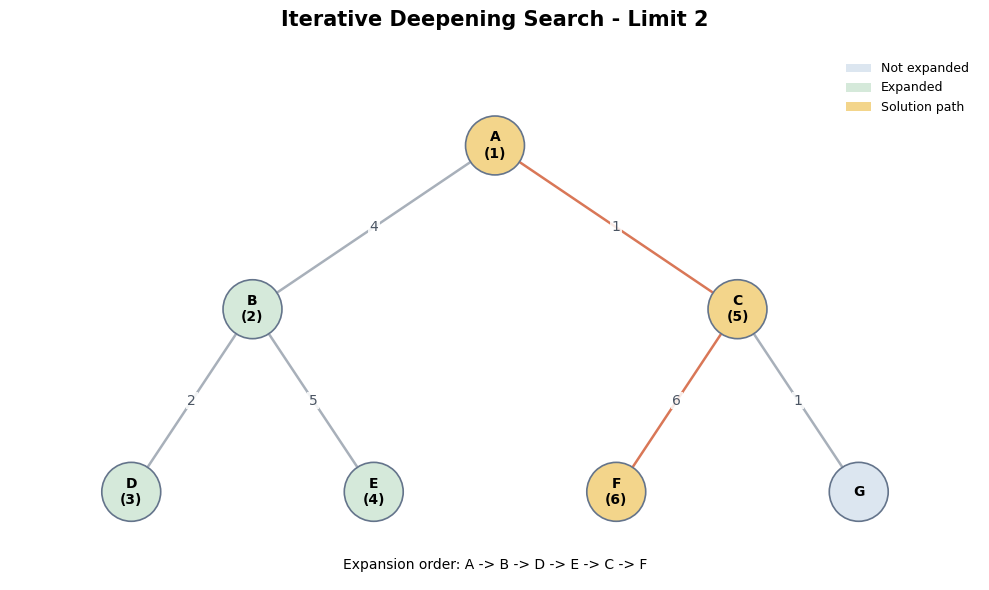

In [23]:

max_depth = 2

for limit in range(max_depth + 1):

    path = [start]
    steps = []

    found = dls(start, goal, limit, path, steps)

    print("\nDepth Limit:", limit)
    print("Expansion Order:", " -> ".join(steps))

    if found:

        print("Goal Found:", True)
        print("Solution Path:", " -> ".join(path))

        draw_graph(
            steps,
            path,
            f"Iterative Deepening Search - Limit {limit}"
        )

        break

    else:

        print("Goal Found:", False)
        print("Solution Path: Not Found")

        draw_graph(
            steps,
            [],
            f"Iterative Deepening Search - Limit {limit}"
        )


Expansion Order: A -> C -> G -> B -> D -> F
Goal Found: True
Solution Path: A -> C -> F
Total Path Cost: 7


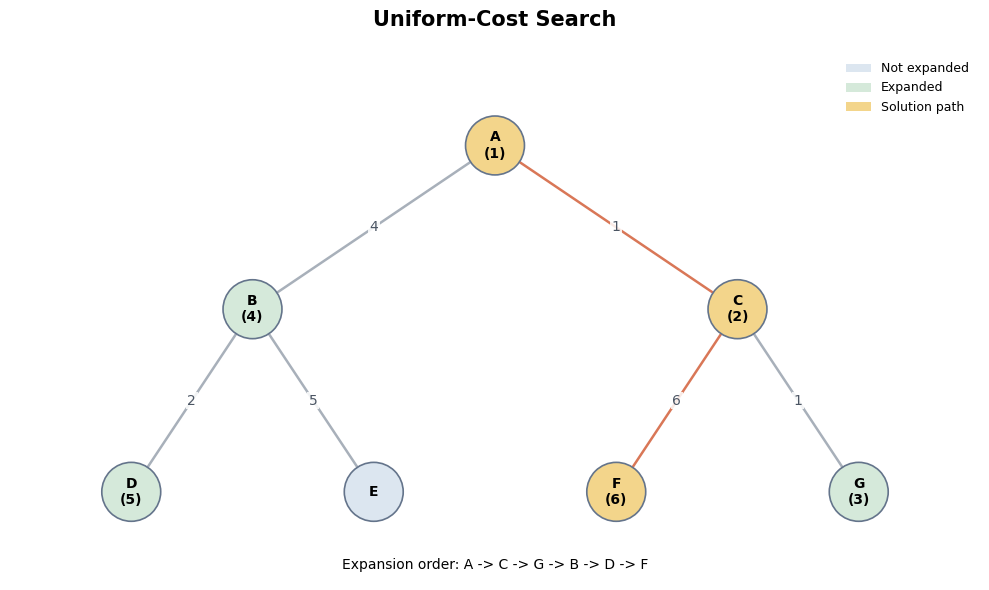

In [24]:

def ucs(start, goal):

    priority_queue = [(0, start)]

    best_cost = {start: 0}
    parent = {start: None}
    steps = []

    while priority_queue:

        cost, node = heapq.heappop(priority_queue)

        if cost != best_cost[node]:
            continue

        steps.append(node)

        if node == goal:
            break

        for child in graph[node]:

            edge_cost = G[node][child]["weight"]
            new_cost = cost + edge_cost

            if child not in best_cost or new_cost < best_cost[child]:

                best_cost[child] = new_cost
                parent[child] = node

                heapq.heappush(
                    priority_queue,
                    (new_cost, child)
                )

    found = bool(steps) and steps[-1] == goal
    path = make_path(parent, goal) if found else []

    print("Expansion Order:", " -> ".join(steps))
    print("Goal Found:", found)

    if found:
        print("Solution Path:", " -> ".join(path))
        print("Total Path Cost:", best_cost[goal])

    else:
        print("Solution Path: Not Found")

    draw_graph(steps, path, "Uniform-Cost Search")


ucs(start, goal)
